# SiN Photonic-Crystal Nanocavities I — Band Gaps and Mirrors

Noda, Fujita and Asano's review (*Nat. Photon.* 1, 449 (2007)) shows how photonic-crystal
nanocavities control spontaneous emission: a cavity of quality factor Q and mode volume V
enhances the emission rate of an emitter on resonance by the Purcell factor

$$F = \frac{3}{4\pi^2}\left(\frac{\lambda}{n}\right)^3 \frac{Q}{V}.$$

Their cavities are silicon 2D slab cavities (L3, double heterostructure) with Q ~ 10⁶ in the
near infrared. This series asks how far the same ideas go in **silicon nitride in the visible**,
where emitters such as the NV centre in diamond (zero-phonon line 637 nm) sit and silicon
absorbs. SiN's index (n ≈ 2.0) is much lower than silicon's (3.5), which weakens both the
in-plane band gap and the out-of-plane confinement by total internal reflection. Two cavity
families are compared:

| family | structure | reference designs |
|---|---|---|
| **L3** (2D slab) | three missing holes in a triangular air-hole lattice, end holes shifted outward | Akahane et al., *Nature* 425, 944 (2003); Minkov & Savona, *Sci. Rep.* 4, 5124 (2014) |
| **Nanobeam** (1D) | a row of holes in a narrow ridge, tapered toward the centre | McCutcheon & Lončar, *Opt. Express* 16, 19136 (2008); Quan & Lončar, *Opt. Express* 19, 18529 (2011) |

**Platform:** a suspended 200 nm stoichiometric LPCVD Si₃N₄ membrane in air (the thickness of
the McCutcheon–Lončar design), n = 2.0, design wavelength 637 nm, smallest feature ≥ 50 nm
(e-beam lithography). Sources and their tiers: `sin_cavity/literature.md`.

This notebook prepares both designs from unit-cell band structures (MPB): the guided band gap
of the triangular-lattice slab (L3) and the band edges and mirror strength of one nanobeam
period (nanobeam taper). Notebook 02 builds the L3 cavity, notebook 03 the nanobeam and the
final comparison.

**Model:** 3D, bulk SiN index 2.0 and air, non-dispersive and lossless. This deviates from the
toolkit's 2D effective-index convention: a slab cavity's Q is set by radiation out of the
plane, which a 2D model cannot represent (see `src/pic_toolkit/meep_sim/phc_cavity.py`).
Lengths in µm unless stated, frequencies in c/a (lattice) or c/µm.

**Kernel:** `mp` conda env, run from `sin_cavity/notebooks/`. The band data are produced by
`scripts/slab_gap_map.py` and `scripts/design_nanobeam.py` and cached in `data/`.
**Do not use "Run All."** Run the cells in order and read each result before going on.

## 0. Setup

In [1]:
# Imports, plotting style and cached data locations.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Circle, Polygon, Rectangle

from pic_toolkit import style
from pic_toolkit.meep_sim import phc_cavity as pc

style.apply_style()
DATA = Path.cwd().parent / "data"
F_RES = 1 / pc.LAMBDA0            # design frequency, c/um
print(f"n = {pc.N_SIN}, membrane t = {pc.T_SLAB * 1e3:.0f} nm, design wavelength {pc.LAMBDA0 * 1e3:.0f} nm")

SIN_FC = style.COLOR_STEEL + "55"            # SiN membrane fill (same shade as notebook 02)


def draw_slab_lattice(ax, r_a, xlim=(-2.5, 2.5), ylim=(-1.75, 1.75)):
    # Triangular air-hole lattice (lengths in units of a, nearest neighbours along x), clipped
    # to a rectangle of SiN; outside the rectangle the axes stay white for labels.
    rect = Rectangle((xlim[0], ylim[0]), xlim[1] - xlim[0], ylim[1] - ylim[0], fc=SIN_FC, ec="none")
    ax.add_patch(rect)
    for j in range(-4, 5):
        for i in range(-6, 7):
            hole = Circle(((i + j / 2), j * np.sqrt(3) / 2), r_a, fc="white", ec="k", lw=0.5)
            ax.add_patch(hole)
            hole.set_clip_path(rect)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)


def draw_beam(ax, holes, w, x_range, colors=None, equal=True):
    # Nanobeam top view (um): ridge of width w along x, holes (x > 0 list mirrored to x < 0).
    ax.add_patch(Rectangle((x_range[0], -w / 2), x_range[1] - x_range[0], w, fc=SIN_FC, ec="k", lw=0.6))
    for k, (x, r) in enumerate(holes):
        fc = colors[k] if colors is not None else "white"
        for sx in (1, -1):
            if x_range[0] - r < sx * x < x_range[1] + r:
                ax.add_patch(Circle((sx * x, 0), r, fc=fc, ec="k", lw=0.5))
    ax.set_xlim(*x_range)
    if equal:
        ax.set_aspect("equal")

n = 2.0, membrane t = 200 nm, design wavelength 637 nm


> **STOP -- the slab gap map is 138 MPB runs (≈ 70 min, `scripts/slab_gap_map.py`), cached in
> `data/bands/slab_gap.npz`.** The cells below only read the cache.

## 1. Triangular air-hole lattice in the SiN membrane

**Structure.** The L3 cavity of notebook 02 sits in a triangular lattice of air holes (radius r,
lattice constant a) etched through a suspended 200 nm SiN membrane, with air above and below
(figure below). MPB computes the bands of one unit cell (one hole, dashed), repeated in the plane,
along the edge of the irreducible Brillouin zone Γ → M → K → Γ.

**TE-like and TM-like modes.** A membrane with air on both sides is mirror-symmetric about its
mid-plane z = 0, so its modes split into two families:
- **TE-like** (z-even): the electric field lies mostly in the slab plane (Ex, Ey); H is mostly
  along z.
- **TM-like** (z-odd): the electric field points mostly along z.

A lattice of air holes in a dielectric opens a band gap for TE-like modes, and hardly any for
TM-like modes. The L3 mode is TE-like (Ey at the cavity centre), so the TE-like gap is the
one that matters. Both families are shown below for comparison.

**Guided gap.** In a slab only the part of the band structure **below the light line**
(f < |k| in c/a units) is guided; modes above it leak into the air. The **guided TE-like gap**
is the frequency range between the top of band 1 and the lowest guided point of band 2. No
guided TE-like mode exists there, so a defect mode placed inside it cannot spread into the
crystal and can only lose energy by radiating out of the plane. Because the membrane thickness
is fixed at 200 nm, t/a changes with the lattice constant, so the gap was computed for five
values of a as well as for r/a from 0.20 to 0.42 in steps of 0.01.

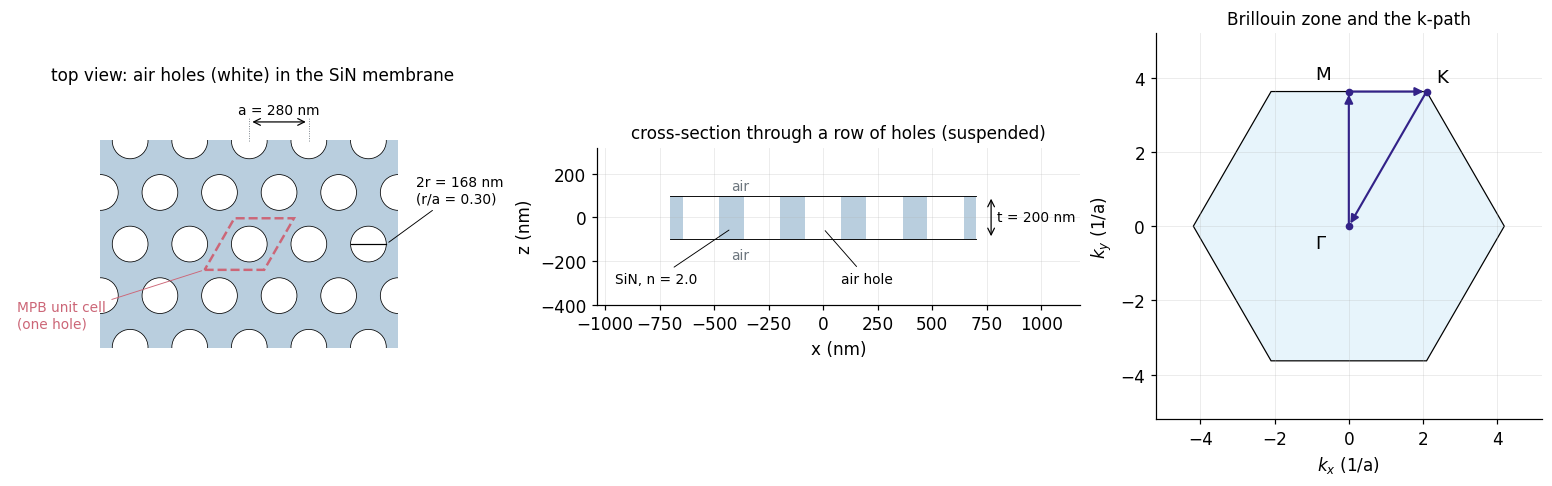

In [2]:
# The structure of Section 1: top view of the hole lattice, cross-section of the membrane, and
# the Brillouin zone whose edge (Gamma-M-K-Gamma) the band diagrams below follow.
r_show, a_show = 0.30, 0.28                   # r/a and a (um) of the example drawn here
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), layout="constrained",
                         gridspec_kw=dict(width_ratios=[1.25, 1.25, 1]))

ax = axes[0]
draw_slab_lattice(ax, r_show)
cell = np.array([[-0.75, -np.sqrt(3) / 4], [0.25, -np.sqrt(3) / 4], [0.75, np.sqrt(3) / 4], [-0.25, np.sqrt(3) / 4]])
ax.add_patch(Polygon(cell, closed=True, fill=False, ec=style.COLOR_ROSE, lw=1.6, ls="--"))
y_top = 1.75 + 0.3                             # dimension line for a, above the membrane
for x0 in (0, 1):
    ax.plot([x0, x0], [np.sqrt(3), y_top + 0.08], color=style.COLOR_REFERENCE, lw=0.6, ls=":")
ax.annotate("", (1, y_top), (0, y_top), arrowprops=dict(arrowstyle="<->", color="k", lw=0.8))
ax.text(0.5, y_top + 0.08, f"a = {a_show * 1e3:.0f} nm", ha="center", va="bottom", fontsize=9)
ax.plot([2 - r_show, 2 + r_show], [0, 0], color="k", lw=0.8)        # a diameter, drawn inside the hole
ax.annotate(f"2r = {2 * r_show * a_show * 1e3:.0f} nm\n(r/a = {r_show:.2f})", (2 + r_show, 0), (2.8, 0.9),
            fontsize=9, va="center", arrowprops=dict(arrowstyle="-", color="k", lw=0.6))
ax.annotate("MPB unit cell\n(one hole)", (-0.75, -np.sqrt(3) / 4), (-3.9, -1.2), fontsize=9,
            color=style.COLOR_ROSE, va="center", arrowprops=dict(arrowstyle="-", color=style.COLOR_ROSE, lw=0.6))
ax.set_xlim(-4.0, 4.1); ax.set_ylim(-2.0, 2.6)
ax.set_title("top view: air holes (white) in the SiN membrane", fontsize=11)

ax = axes[1]
t_nm, a_nm, r_nm = pc.T_SLAB * 1e3, a_show * 1e3, r_show * a_show * 1e3
ax.add_patch(Rectangle((-2.5 * a_nm, -t_nm / 2), 5 * a_nm, t_nm, fc=SIN_FC, ec="none"))
for i in range(-2, 3):
    ax.add_patch(Rectangle((i * a_nm - r_nm, -t_nm / 2), 2 * r_nm, t_nm, fc="white", ec="none"))
ax.plot([-2.5 * a_nm, 2.5 * a_nm], [t_nm / 2] * 2, [-2.5 * a_nm, 2.5 * a_nm], [-t_nm / 2] * 2, color="k", lw=0.6)
ax.annotate("", (2.75 * a_nm, t_nm / 2), (2.75 * a_nm, -t_nm / 2), arrowprops=dict(arrowstyle="<->", lw=0.8))
ax.text(2.85 * a_nm, 0, f"t = {t_nm:.0f} nm", va="center", fontsize=9)
ax.text(-1.5 * a_nm, 0.62 * t_nm, "air", fontsize=9, color=style.COLOR_REFERENCE)
ax.text(-1.5 * a_nm, -0.95 * t_nm, "air", fontsize=9, color=style.COLOR_REFERENCE)
ax.annotate(f"SiN, n = {pc.N_SIN:.1f}", (-1.5 * a_nm, -t_nm / 4), (-3.4 * a_nm, -1.5 * t_nm), fontsize=9,
            arrowprops=dict(arrowstyle="-", lw=0.6))
ax.annotate("air hole", (0, -t_nm / 4), (0.3 * a_nm, -1.5 * t_nm), fontsize=9,
            arrowprops=dict(arrowstyle="-", lw=0.6))
ax.set_xlim(-3.7 * a_nm, 4.2 * a_nm); ax.set_ylim(-2 * t_nm, 1.6 * t_nm); ax.set_aspect("equal")
ax.set_xlabel("x (nm)"); ax.set_ylabel("z (nm)")
ax.set_title("cross-section through a row of holes (suspended)", fontsize=11)

ax = axes[2]
# Brillouin zone of this lattice: hexagon with K on the kx axis and M on the ky axis.
kK, kM = 4 * np.pi / 3, 2 * np.pi / np.sqrt(3)            # |K| and |M| in 1/a
ang = np.deg2rad(np.arange(0, 360, 60))
ax.add_patch(Polygon(np.c_[kK * np.cos(ang), kK * np.sin(ang)], closed=True, fc=style.COLOR_CYAN + "33", ec="k", lw=0.8))
path = np.array([[0, 0], [0, kM], [kK * np.cos(np.pi / 3), kK * np.sin(np.pi / 3)], [0, 0]])
for p, q in zip(path[:-1], path[1:]):
    ax.annotate("", q, p, arrowprops=dict(arrowstyle="-|>", color=style.COLOR_INDIGO, lw=1.4))
for (x, y), lab, off in zip(path[:3], "ΓMK", ((-0.9, -0.6), (-0.9, 0.35), (0.25, 0.25))):
    ax.plot(x, y, "o", color=style.COLOR_INDIGO, ms=4)
    ax.text(x + off[0], y + off[1], lab, fontsize=12)
ax.set_xlim(-5.2, 5.2); ax.set_ylim(-5.2, 5.2); ax.set_aspect("equal")
ax.set_xlabel("$k_x$ (1/a)"); ax.set_ylabel("$k_y$ (1/a)")
ax.set_title("Brillouin zone and the k-path", fontsize=11)
plt.show()

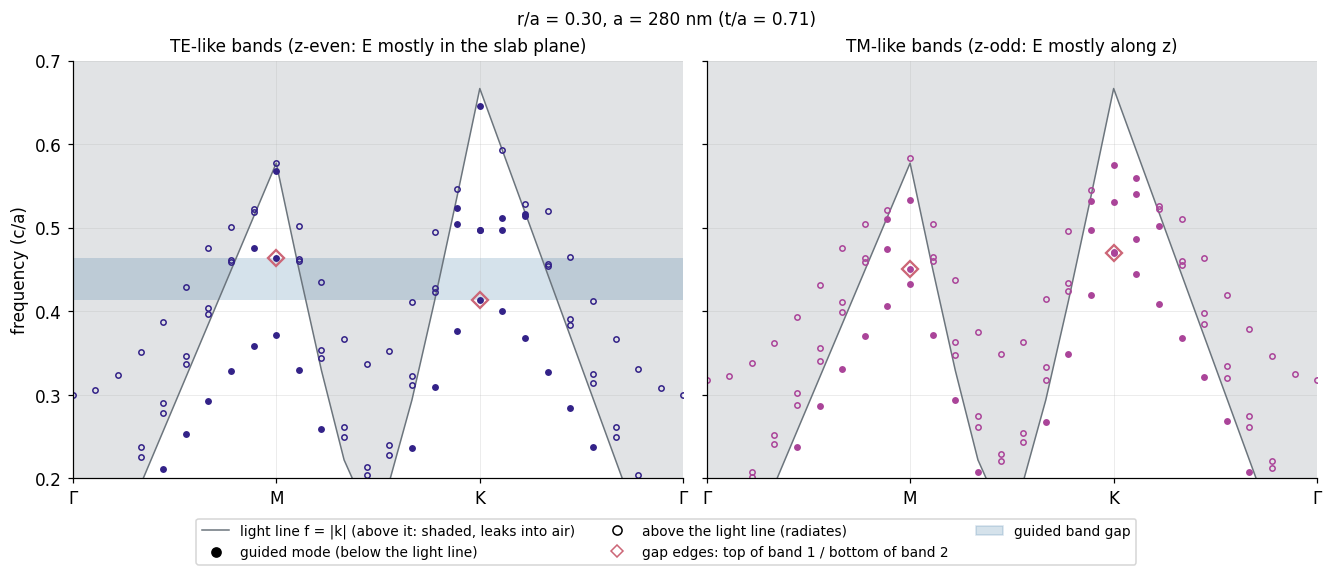

TE-like: top of band 1 0.4136 c/a, bottom of band 2 0.4640 c/a -> guided gap 11.5 %
TM-like: top of band 1 0.4704 c/a, bottom of band 2 0.4508 c/a -> no guided gap (bands overlap)


In [3]:
# Band diagrams of the r/a = 0.30, a = 280 nm lattice: TE-like (left) and TM-like (right).
B = np.load(DATA / "bands" / "slab_gap.npz")
R_A, A_UM, kmag = B["r_a"], B["a_um"], B["kmag"]
i_r, j_a = int(np.argmin(abs(R_A - 0.30))), int(np.argmin(abs(A_UM - float(B["a_tm"]))))
kk = np.arange(len(kmag))
n_seg = (len(kk) - 1) // 3

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained", sharey=True)
cases = ((axes[0], B["bands"][i_r, j_a], B["gap_lo"][i_r, j_a], B["gap_hi"][i_r, j_a],
          "TE-like bands (z-even: E mostly in the slab plane)", style.COLOR_INDIGO),
         (axes[1], B["bands_tm"][i_r], B["gap_lo_tm"][i_r], B["gap_hi_tm"][i_r],
          "TM-like bands (z-odd: E mostly along z)", style.COLOR_PURPLE))
for ax, bands, lo, hi, title, col in cases:
    ax.fill_between(kk, kmag, 0.8, color=style.COLOR_REFERENCE, alpha=0.2, lw=0)
    ax.plot(kk, kmag, color=style.COLOR_REFERENCE, lw=1)
    if hi > lo:
        ax.axhspan(lo, hi, color=style.COLOR_STEEL, alpha=0.2, lw=0)
    for n in range(bands.shape[1]):
        guided = bands[:, n] < kmag
        ax.plot(kk[guided], bands[guided, n], "o", ms=3.5, color=col)
        ax.plot(kk[~guided], bands[~guided, n], "o", ms=3.5, mfc="none", color=col)
    # The two points that set the guided gap: top of band 1, bottom of band 2 (below the light line).
    for n, f_edge in ((0, lo), (1, hi)):
        k_edge = np.argmin(abs(np.where(bands[:, n] < kmag, bands[:, n], np.inf) - f_edge))
        ax.plot(kk[k_edge], f_edge, "D", ms=7, mfc="none", mec=style.COLOR_ROSE, mew=1.5)
    ax.set_xticks([0, n_seg, 2 * n_seg, 3 * n_seg], ["Γ", "M", "K", "Γ"])
    ax.set_xlim(0, len(kk) - 1); ax.set_ylim(0.2, 0.7)
    ax.set_title(title, fontsize=11)
axes[0].set_ylabel("frequency (c/a)")
handles = [plt.Line2D([], [], color=style.COLOR_REFERENCE, lw=1, label="light line f = |k| (above it: shaded, leaks into air)"),
           plt.Line2D([], [], marker="o", ls="none", color="k", label="guided mode (below the light line)"),
           plt.Line2D([], [], marker="o", ls="none", mfc="none", color="k", label="above the light line (radiates)"),
           plt.Line2D([], [], marker="D", ls="none", mfc="none", mec=style.COLOR_ROSE, label="gap edges: top of band 1 / bottom of band 2"),
           plt.Rectangle((0, 0), 1, 1, color=style.COLOR_STEEL, alpha=0.2, label="guided band gap")]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3, fontsize=9)
fig.suptitle(f"r/a = {R_A[i_r]:.2f}, a = {A_UM[j_a] * 1e3:.0f} nm (t/a = {pc.T_SLAB / A_UM[j_a]:.2f})", fontsize=11)
fig.savefig(DATA / "fig_slab_bands.png", dpi=150, bbox_inches="tight")
plt.show()
for name, lo, hi in (("TE-like", B["gap_lo"][i_r, j_a], B["gap_hi"][i_r, j_a]),
                     ("TM-like", B["gap_lo_tm"][i_r], B["gap_hi_tm"][i_r])):
    print(f"{name}: top of band 1 {lo:.4f} c/a, bottom of band 2 {hi:.4f} c/a -> "
          + (f"guided gap {200 * (hi - lo) / (hi + lo):.1f} %" if hi > lo else "no guided gap (bands overlap)"))

**Reading the band diagrams.** Each point is one mode at one wavevector on the Γ–M–K–Γ path. Filled
points lie below the light line (guided), open points above it (they radiate into the air,
grey region). For the TE-like modes (left), band 1 ends at 0.414 c/a (at K) and band 2
starts at 0.464 c/a (at M). Between the two diamonds there is no guided mode: this is the guided gap
(11.5 % of its mid-frequency). The TM-like bands (right) have no guided gap: the top of band 1 (0.470 c/a) lies above the bottom of band 2 (0.451 c/a), so a guided TM-like mode exists at every frequency of this range, and the same holds for every r/a scanned (the bands overlap by 3–7 %).
The L3 mode is therefore designed into the TE-like gap.

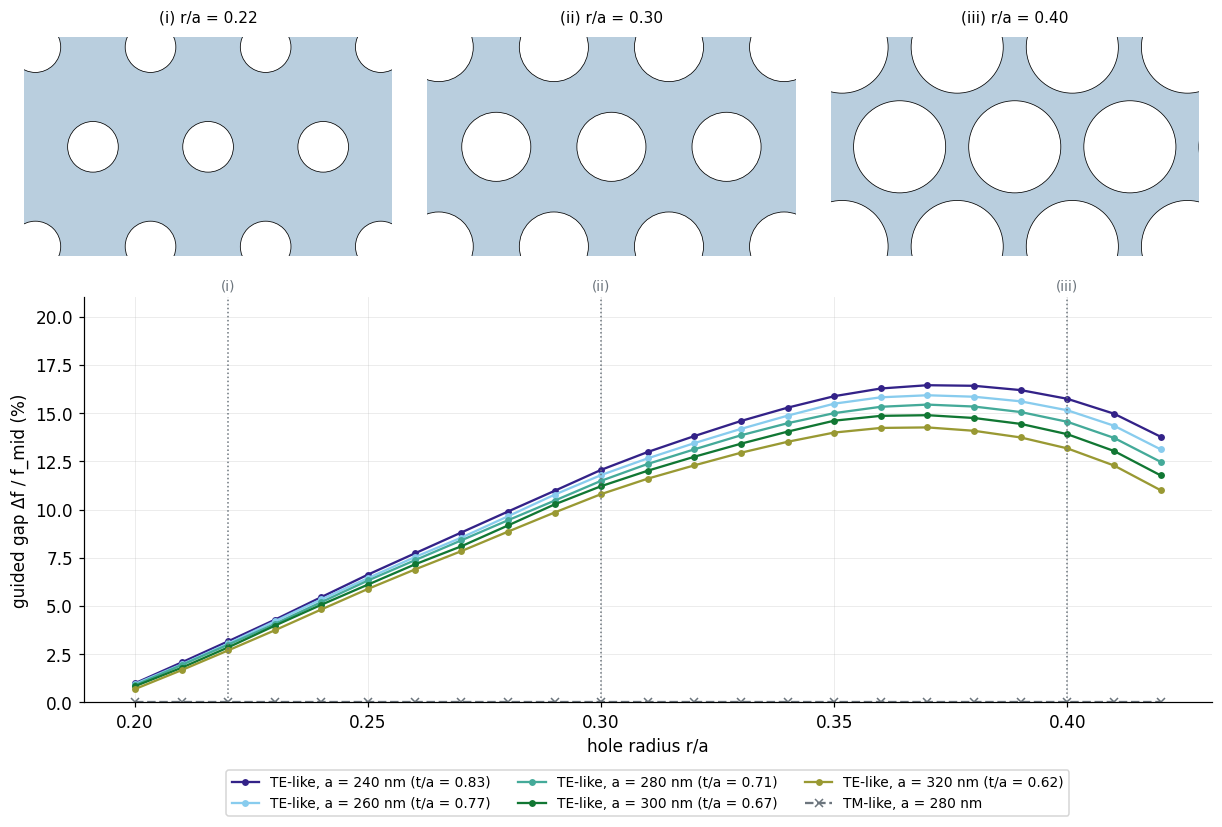

In [4]:
# Guided gap vs r/a for five lattice constants (TE-like), and the TM-like "gap" at a = 280 nm.
# Top row: the lattice at three of the scanned r/a values, to show what the scan changes.
def gap_pct(lo, hi):
    return np.clip(200 * (hi - lo) / (hi + lo), 0, None)        # 0 where the bands overlap


R_SHOW = (0.22, 0.30, 0.40)
fig = plt.figure(figsize=(11, 7.4), layout="constrained")
top, bottom = fig.subfigures(2, 1, height_ratios=[1, 2.1])
for ax, r_a, lab in zip(top.subplots(1, 3), R_SHOW, ("i", "ii", "iii")):
    draw_slab_lattice(ax, r_a, xlim=(-1.6, 1.6), ylim=(-0.95, 0.95))
    ax.set_xlim(-1.7, 1.7); ax.set_ylim(-1.0, 1.0)
    ax.set_title(f"({lab}) r/a = {r_a:.2f}", fontsize=10)

ax1 = bottom.subplots()
for j, a in enumerate(A_UM):
    ax1.plot(R_A, gap_pct(B["gap_lo"][:, j], B["gap_hi"][:, j]), "o-", color=style.COLOR_CYCLE[j], ms=3.5,
             label=f"TE-like, a = {a * 1e3:.0f} nm (t/a = {pc.T_SLAB / a:.2f})")
ax1.plot(R_A, gap_pct(B["gap_lo_tm"], B["gap_hi_tm"]), "x--", color=style.COLOR_REFERENCE, ms=5,
         label=f"TM-like, a = {float(B['a_tm']) * 1e3:.0f} nm")
for r_a, lab in zip(R_SHOW, ("i", "ii", "iii")):         # the three lattices drawn above
    ax1.axvline(r_a, color=style.COLOR_REFERENCE, ls=":", lw=1)
    ax1.text(r_a, 1.01, f"({lab})", ha="center", va="bottom", fontsize=9, color=style.COLOR_REFERENCE,
             transform=ax1.get_xaxis_transform())
ax1.set_xlabel("hole radius r/a"); ax1.set_ylabel("guided gap Δf / f_mid (%)"); ax1.set_ylim(0, 21)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=9)
fig.savefig(DATA / "fig_slab_gap_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# TE-like guided gap edges at r/a = 0.30 in wavelength: which lattice constant puts 637 nm inside the gap.
for j, a in enumerate(A_UM):
    l_hi, l_lo = a / B["gap_lo"][i_r, j] * 1e3, a / B["gap_hi"][i_r, j] * 1e3
    print(f"a = {a * 1e3:.0f} nm: gap {B['gap_lo'][i_r, j]:.4f}-{B['gap_hi'][i_r, j]:.4f} c/a "
          f"= {l_lo:.0f}-{l_hi:.0f} nm" + ("  <- contains 637 nm" if l_lo < 637 < l_hi else ""))

a = 240 nm: gap 0.4040-0.4559 c/a = 526-594 nm
a = 260 nm: gap 0.4091-0.4603 c/a = 565-636 nm
a = 280 nm: gap 0.4136-0.4640 c/a = 603-677 nm  <- contains 637 nm
a = 300 nm: gap 0.4188-0.4686 c/a = 640-716 nm
a = 320 nm: gap 0.4239-0.4723 c/a = 678-755 nm


The TE-like guided gap grows from ≈ 1 % at r/a = 0.20 to its maximum at r/a = 0.37: 16.4 % for
a = 240 nm, falling to 14.3 % for a = 320 nm. Beyond that it shrinks again as the walls between
holes become thin. Two trends explain the shape:
- **larger holes** remove dielectric, which raises the air band (band 2) more than the dielectric
  band (band 1), so the gap widens until the holes nearly touch;
- **larger a** at fixed 200 nm thickness makes the membrane thinner in units of a (t/a 0.83 →
  0.63). The mode then spreads further into the air, the contrast it sees falls, and the gap shrinks.

The TM-like bands have no guided gap anywhere in the scan (dashed line at 0). Much of the band structure
near Γ sits above the light line: with n = 2.0 the light cone takes a large share of k-space,
which is what limits the Q of a SiN slab cavity.

The L3 design uses **r/a = 0.30** (lattice (ii) above), which keeps an 11–12 % gap (10.8–12.1 %
over the five a) while leaving walls of 0.4a (≈ 110 nm) between neighbouring holes, well above
the 50 nm e-beam limit. Removing holes adds dielectric, so the L3 defect mode is pulled down from
the air band and sits in the lower part of the gap (f ≈ 0.415 c/a, notebook 02). With
a = 266.6 nm, chosen in notebook 02 from the resonance itself, the gap spans ≈ 580–650 nm and
the mode lands at 642 nm.

> **STOP -- 11 MPB runs of one nanobeam period (≈ 3 min, `scripts/design_nanobeam.py`),
> cached in `data/nanobeam/design_band_edges.npz`.**

## 2. Nanobeam unit cell: band edges and mirror strength

A nanobeam cavity is a Bragg mirror in a ridge waveguide (300 nm × 200 nm, figure below). One
period of length a = 250 nm with a hole of radius r has a band gap for TE-like modes (E mostly
across the beam, along y, as in the cavity mode) at the X point (k = π/a), between the
**dielectric band edge** f₁ (field concentrated in the SiN between holes) and the **air band edge**
f₂ (field concentrated in the holes). The hole radius is scanned from 50 to 100 nm; the three
drawings (i)–(iii) show what that changes. Quan & Lončar define the
**mirror strength** at the resonance frequency f_res,

$$\gamma = \sqrt{\left(\frac{f_2 - f_1}{f_2 + f_1}\right)^2 - \left(\frac{f_{res} - f_0}{f_0}\right)^2}, \qquad f_0 = \frac{f_1 + f_2}{2},$$

the decay constant of the field per period inside the mirror (γ = 0 when f_res lies outside the
gap). Their recipe fixes two radii from this map:
- the **centre radius r_c**, where the dielectric band edge equals f_res — the cavity mode
  forms from that band edge;
- the **mirror radius r_m**, where γ is largest.

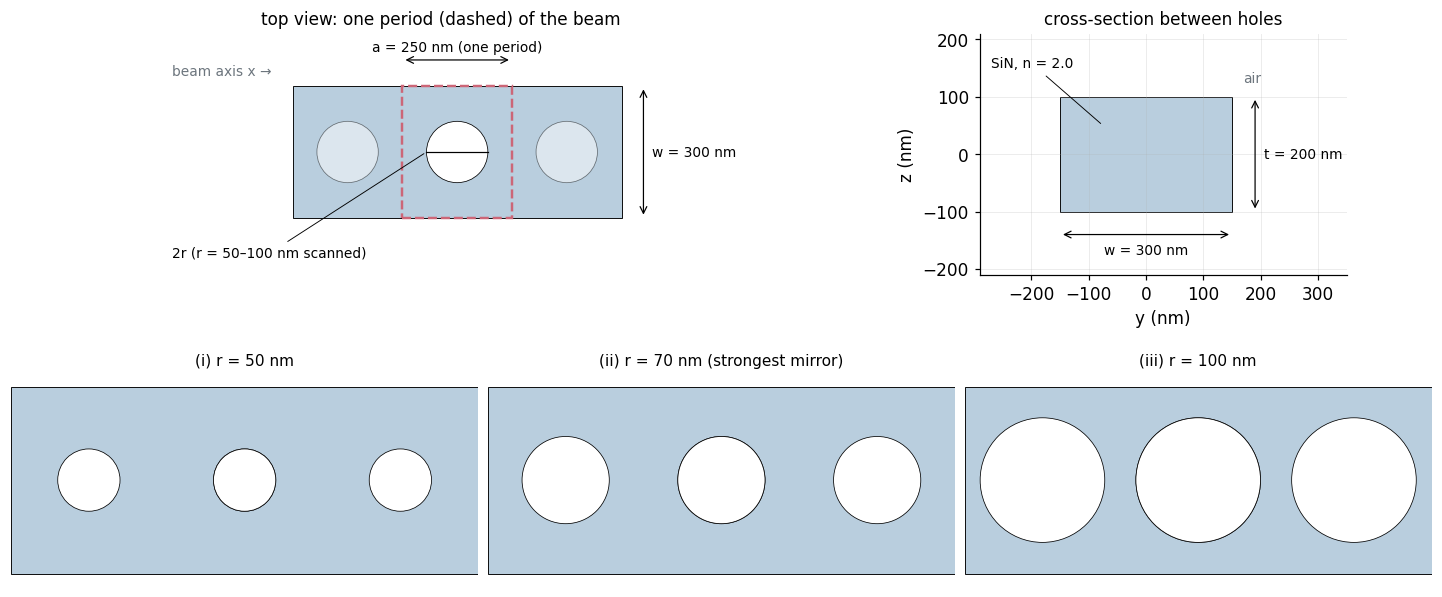

In [6]:
# The structure of Section 2: one period of the nanobeam (top view and cross-section) and, below,
# three periods at the smallest, the strongest-mirror and the largest radius of the scan.
E = np.load(DATA / "nanobeam" / "design_band_edges.npz")
a_nb, w_nb, t_nb = float(E["a"]) * 1e3, float(E["w"]) * 1e3, float(E["t"]) * 1e3   # nm
fig = plt.figure(figsize=(13, 5.6), layout="constrained")
top, bottom = fig.subfigures(2, 1, height_ratios=[1.15, 1])
ax0, ax1 = top.subplots(1, 2, gridspec_kw=dict(width_ratios=[1.6, 1]))

# One period, top view, r = 70 nm, with its neighbours faded.
r0 = 70
ax0.add_patch(Rectangle((-1.5 * a_nb, -w_nb / 2), 3 * a_nb, w_nb, fc=SIN_FC, ec="k", lw=0.6))
for i in (-1, 0, 1):
    ax0.add_patch(Circle((i * a_nb, 0), r0, fc="white", ec="k", lw=0.5, alpha=1 if i == 0 else 0.5))
ax0.add_patch(Rectangle((-a_nb / 2, -w_nb / 2), a_nb, w_nb, fill=False, ec=style.COLOR_ROSE, lw=1.6, ls="--"))
y_dim = w_nb / 2 + 60
ax0.annotate("", (a_nb / 2, y_dim), (-a_nb / 2, y_dim), arrowprops=dict(arrowstyle="<->", lw=0.8))
ax0.text(0, y_dim + 12, f"a = {a_nb:.0f} nm (one period)", ha="center", va="bottom", fontsize=9)
ax0.annotate("", (1.5 * a_nb + 50, w_nb / 2), (1.5 * a_nb + 50, -w_nb / 2), arrowprops=dict(arrowstyle="<->", lw=0.8))
ax0.text(1.5 * a_nb + 70, 0, f"w = {w_nb:.0f} nm", va="center", fontsize=9)
ax0.plot([-r0, r0], [0, 0], color="k", lw=0.8)
ax0.annotate(f"2r (r = 50–100 nm scanned)", (-r0, 0), (-2.6 * a_nb, -w_nb / 2 - 90), fontsize=9,
             arrowprops=dict(arrowstyle="-", lw=0.6))
ax0.text(-2.6 * a_nb, w_nb / 2 + 25, "beam axis x →", fontsize=9, color=style.COLOR_REFERENCE)
ax0.set_xlim(-2.7 * a_nb, 2.4 * a_nb); ax0.set_ylim(-w_nb / 2 - 130, w_nb / 2 + 120); ax0.set_aspect("equal")
ax0.set_xticks([]); ax0.set_yticks([]); [s.set_visible(False) for s in ax0.spines.values()]
ax0.set_title("top view: one period (dashed) of the beam", fontsize=11)

# Cross-section between two holes: a 300 nm x 200 nm SiN ridge suspended in air.
ax1.add_patch(Rectangle((-w_nb / 2, -t_nb / 2), w_nb, t_nb, fc=SIN_FC, ec="k", lw=0.6))
ax1.annotate("", (w_nb / 2, -t_nb / 2 - 40), (-w_nb / 2, -t_nb / 2 - 40), arrowprops=dict(arrowstyle="<->", lw=0.8))
ax1.text(0, -t_nb / 2 - 55, f"w = {w_nb:.0f} nm", ha="center", va="top", fontsize=9)
ax1.annotate("", (w_nb / 2 + 40, t_nb / 2), (w_nb / 2 + 40, -t_nb / 2), arrowprops=dict(arrowstyle="<->", lw=0.8))
ax1.text(w_nb / 2 + 55, 0, f"t = {t_nb:.0f} nm", va="center", fontsize=9)
ax1.text(w_nb / 2 + 20, t_nb / 2 + 25, "air", fontsize=9, color=style.COLOR_REFERENCE)
ax1.annotate(f"SiN, n = {pc.N_SIN:.1f}", (-w_nb / 4, t_nb / 4), (-w_nb / 2 - 120, t_nb / 2 + 45), fontsize=9,
             va="bottom", arrowprops=dict(arrowstyle="-", lw=0.6))
ax1.set_xlim(-w_nb / 2 - 140, w_nb / 2 + 200); ax1.set_ylim(-t_nb / 2 - 110, t_nb / 2 + 110); ax1.set_aspect("equal")
ax1.set_xlabel("y (nm)"); ax1.set_ylabel("z (nm)")
ax1.set_title("cross-section between holes", fontsize=11)

# Three periods at three radii: what the scan of Section 2 changes.
for ax, r, lab in zip(bottom.subplots(1, 3), (50, 70, 100), ("i", "ii", "iii")):
    holes = np.array([[0.0, r], [a_nb, r]])              # mirrored to x < 0 by draw_beam
    draw_beam(ax, holes, w_nb, (-1.5 * a_nb, 1.5 * a_nb))
    ax.set_ylim(-w_nb / 2 - 20, w_nb / 2 + 20)
    ax.set_xticks([]); ax.set_yticks([]); [s.set_visible(False) for s in ax.spines.values()]
    ax.set_title(f"({lab}) r = {r} nm" + (" (strongest mirror)" if r == 70 else ""), fontsize=10)
plt.show()

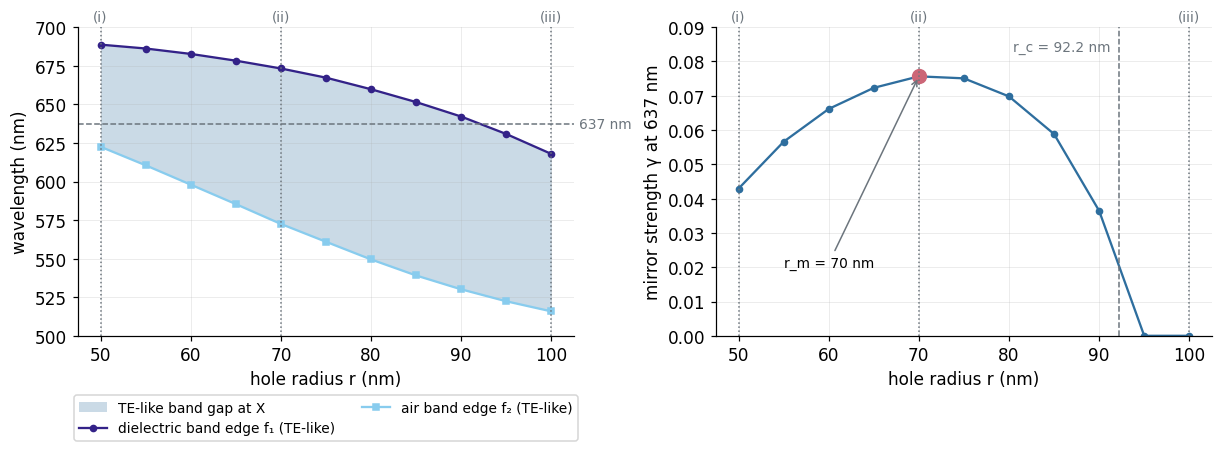

r_c = 92.2 nm (f1 = f_res), r_m = 70 nm (gamma = 0.076), gap at r_m: 572-673 nm


In [7]:
# TE-like band edges at X (in nm) and mirror strength at 637 nm vs hole radius;
# dotted lines: the three radii drawn above.
r_nm, f1, f2, gam = E["r"] * 1e3, E["f1"], E["f2"], E["gamma"]
r_c = float(np.interp(F_RES, f1, E["r"])) * 1e3      # f1 rises with r
r_m = float(r_nm[np.argmax(gam)])

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
ax0.fill_between(r_nm, 1e3 / f2, 1e3 / f1, color=style.COLOR_STEEL, alpha=0.25, lw=0, label="TE-like band gap at X")
ax0.plot(r_nm, 1e3 / f1, "o-", ms=4, color=style.COLOR_INDIGO, label="dielectric band edge f₁ (TE-like)")
ax0.plot(r_nm, 1e3 / f2, "s-", ms=4, color=style.COLOR_CYAN, label="air band edge f₂ (TE-like)")
ax0.axhline(637, color=style.COLOR_REFERENCE, ls="--", lw=1)
ax0.text(1.01, 637, "637 nm", color=style.COLOR_REFERENCE, fontsize=9, va="center", transform=ax0.get_yaxis_transform())
ax0.set_xlabel("hole radius r (nm)"); ax0.set_ylabel("wavelength (nm)"); ax0.set_ylim(500, 700)
ax0.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=9)

ax1.plot(r_nm, gam, "o-", ms=4, color=style.COLOR_STEEL)
ax1.plot([r_m], [gam.max()], "o", ms=9, color=style.COLOR_ROSE)
ax1.axvline(r_c, color=style.COLOR_REFERENCE, ls="--", lw=1)
ax1.annotate(f"r_m = {r_m:.0f} nm", (r_m, gam.max()), (55, 0.02), fontsize=9,
             arrowprops=dict(arrowstyle="->", color=style.COLOR_REFERENCE))
ax1.text(r_c - 1, 0.083, f"r_c = {r_c:.1f} nm", ha="right", fontsize=9, color=style.COLOR_REFERENCE)
ax1.set_xlabel("hole radius r (nm)"); ax1.set_ylabel("mirror strength γ at 637 nm"); ax1.set_ylim(0, 0.09)
for ax in (ax0, ax1):                                   # labels above the axes, off the data
    for r, lab in zip((50, 70, 100), ("i", "ii", "iii")):
        ax.axvline(r, color=style.COLOR_REFERENCE, ls=":", lw=1)
        ax.text(r, 1.01, f"({lab})", ha="center", va="bottom", fontsize=9, color=style.COLOR_REFERENCE,
                transform=ax.get_xaxis_transform())
fig.savefig(DATA / "fig_nanobeam_mirror.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"r_c = {r_c:.1f} nm (f1 = f_res), r_m = {r_m:.0f} nm (gamma = {gam.max():.3f}), "
      f"gap at r_m: {1e3 / f2[np.argmax(gam)]:.0f}-{1e3 / f1[np.argmax(gam)]:.0f} nm")

The mirror is strongest at r = 70 nm (r/a = 0.28), exactly the mirror hole of the
McCutcheon–Lončar design: 637 nm then sits near mid-gap (572–673 nm). The gap is only
≈ 16 % of the mid-gap frequency, so the field decays slowly inside the mirror and SiN
nanobeams need many mirror periods (17 in McCutcheon & Lončar).

## 3. Taper designs

A nanobeam cavity has three parts along the beam (figure below):
- the **cavity centre**: the mode's antinode, between the two innermost holes;
- the **taper**: holes whose size (and, for McCutcheon, period) changes step by step, so that
  the mirror strength grows gradually away from the centre (teal holes);
- the **mirror**: identical holes at the strongest mirror radius r_m = 70 nm (white holes),
  which reflect the field back and hold it in the centre.

Two tapers bring the field from the cavity centre into the mirror:

- **McCutcheon & Lončar (reproduction target).** Four holes whose period and radius both
  shrink toward the centre, (a, r) = (250, 66) → (238, 62) → (226, 58) → (214, 55) nm, a
  cavity gap s between the two innermost holes, and 17 mirror periods (a = 250, r = 70 nm).
- **Own design (Quan–Lončar recipe).** Constant period a = 250 nm, zero cavity length
  (innermost holes at ±a/2), hole filling fraction πr²/(aw) tapered quadratically from r_c to
  r_m over N segments, then 10 mirror holes at r_m. A quadratic filling fraction makes γ
  rise about linearly away from the centre, which gives a Gaussian field envelope and
  suppresses the momentum components inside the light cone. N = 15 and 20 are compared.

McCutcheon & Lončar (s = 95 nm): 21 holes per side, beam length 10.24 um, inner hole r = 55.0 nm at x = 103 nm
own, N = 15: 26 holes per side, beam length 12.89 um, inner hole r = 92.2 nm at x = 125 nm
own, N = 20: 31 holes per side, beam length 15.39 um, inner hole r = 92.2 nm at x = 125 nm


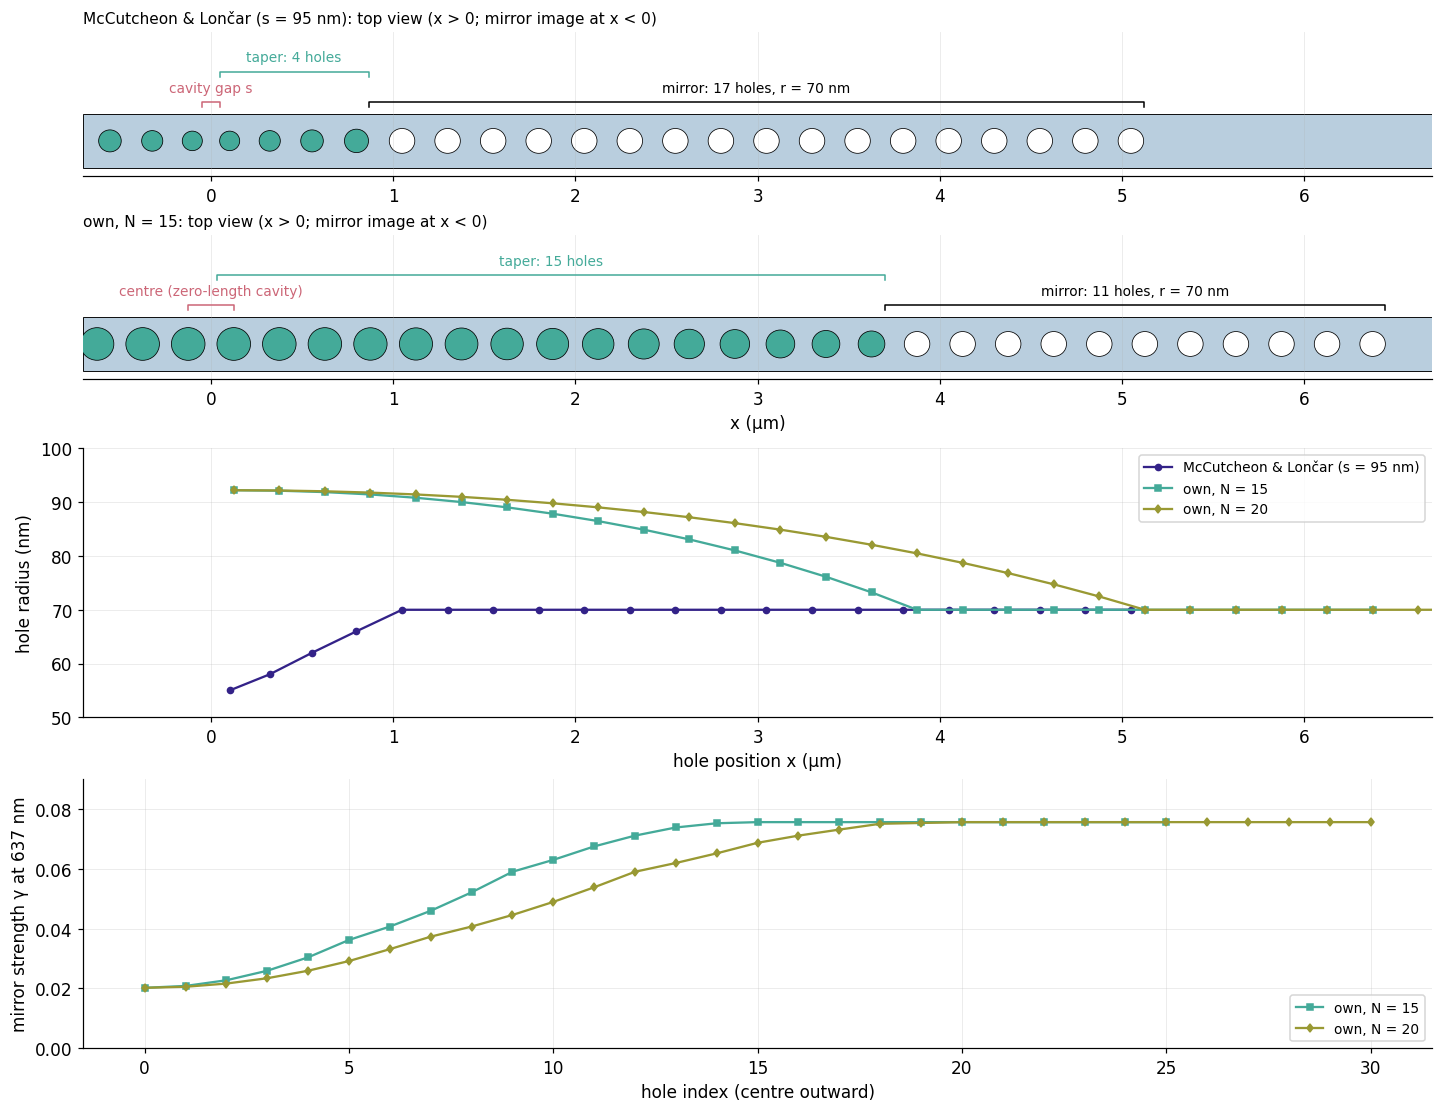

In [8]:
# Where the cavity, the taper and the mirror sit along the beam (top), the hole radius at each
# hole position (middle) and the mirror strength each hole of the own designs would have as a
# uniform mirror (bottom, gamma(r) from Section 2). The beams are mirror-symmetric about x = 0;
# the drawings show x > 0 and the start of the left half.
mc = pc.MCCUTCHEON
designs = {
    "McCutcheon & Lončar (s = 95 nm)": pc.nanobeam_holes(mc["taper"], mc["mirror"], mc["n_mirror"], 0.095, "edge"),
    "own, N = 15": np.load(DATA / "nanobeam" / "design_N15.npy"),
    "own, N = 20": np.load(DATA / "nanobeam" / "design_N20.npy"),
}
r_mirror = mc["mirror"][1]
TAPER_C = style.COLOR_TEAL
XLIM = (-0.7, 6.7)


def bracket(ax, x0, x1, y, text, color="k"):
    # Region marker above the beam: a horizontal bar with end ticks and a label above it.
    ax.plot([x0, x0, x1, x1], [y - 0.03, y, y, y - 0.03], color=color, lw=1)
    ax.text((x0 + x1) / 2, y + 0.04, text, ha="center", va="bottom", fontsize=9, color=color)


fig, axes = plt.subplots(4, 1, figsize=(13, 10), layout="constrained",
                         gridspec_kw=dict(height_ratios=[0.75, 0.75, 1.4, 1.4]))
for ax, name in zip(axes[:2], list(designs)[:2]):
    h = designs[name]
    is_taper = abs(h[:, 1] - r_mirror) > 0.5e-3              # every hole that differs from the mirror hole
    draw_beam(ax, h, mc["w"], XLIM, colors=[TAPER_C if t else "white" for t in is_taper], equal=False)
    x_in, r_in = h[0]
    n_t = int(is_taper.sum())
    x_t = h[n_t - 1, 0] + h[n_t - 1, 1]                        # outer edge of the last taper hole
    y_b = mc["w"] / 2 + 0.07
    if name.startswith("McC"):
        bracket(ax, -(x_in - r_in), x_in - r_in, y_b, "cavity gap s", style.COLOR_ROSE)
    else:
        bracket(ax, -x_in, x_in, y_b, "centre (zero-length cavity)", style.COLOR_ROSE)
    bracket(ax, x_in - r_in, x_t, y_b + 0.17, f"taper: {n_t} holes", TAPER_C)
    bracket(ax, x_t, h[-1, 0] + h[-1, 1], y_b, f"mirror: {len(h) - n_t} holes, r = {r_mirror * 1e3:.0f} nm")
    ax.set_yticks([]); [s.set_visible(False) for s in ax.spines.values() if s.spine_type != "bottom"]
    ax.set_title(f"{name}: top view (x > 0; mirror image at x < 0)", fontsize=10, loc="left")
ax.set_xlabel("x (µm)")

ax0 = axes[2]
for (name, h), c, m in zip(designs.items(), style.COLOR_CYCLE[::2], "osd"):
    ax0.plot(h[:, 0], h[:, 1] * 1e3, m + "-", ms=4, color=c, label=name)
    print(f"{name}: {len(h)} holes per side, beam length {2 * (h[-1, 0] + h[-1, 1]):.2f} um, "
          f"inner hole r = {h[0, 1] * 1e3:.1f} nm at x = {h[0, 0] * 1e3:.0f} nm")
ax0.set_xlim(*XLIM); ax0.set_ylim(50, 100)
ax0.set_xlabel("hole position x (µm)"); ax0.set_ylabel("hole radius (nm)")
ax0.legend(loc="upper right", fontsize=9)

# Same x range in all three upper panels; the beam panels get the y range that makes 1 um in y
# as long as 1 um in x on screen, so the holes are drawn round.
fig.canvas.draw()
for ax in axes[:2]:
    bb = ax.get_window_extent()
    y0 = -mc["w"] / 2 - 0.05
    ax.set_ylim(y0, y0 + (XLIM[1] - XLIM[0]) * bb.height / bb.width)

ax1 = axes[3]
for (name, h), c, m in list(zip(designs.items(), style.COLOR_CYCLE[::2], "osd"))[1:]:
    ax1.plot(np.arange(len(h)), np.interp(h[:, 1], E["r"], E["gamma"]), m + "-", ms=4, color=c, label=name)
ax1.set_xlabel("hole index (centre outward)"); ax1.set_ylabel("mirror strength γ at 637 nm")
ax1.set_ylim(0, 0.09)
ax1.legend(loc="lower right", fontsize=9)
fig.savefig(DATA / "fig_nanobeam_tapers.png", dpi=150, bbox_inches="tight")
plt.show()

In the drawings, teal holes form the taper and white holes the mirror; each beam continues as its
mirror image at x < 0. The McCutcheon taper is short (four holes, radius rising from 55 to 70 nm
toward the mirror) and changes both a and r; the own designs keep a
fixed and spread the taper over 15 or 20 holes (radius falling from 92 to 70 nm), so their mirror strength climbs smoothly from
near zero at the centre (γ is interpolated on the 5 nm grid of Section 2, hence the small
non-zero start) to the full γ ≈ 0.076, roughly linearly over the middle of the taper. The cost is length: about 13–15 µm
instead of ≈ 10 µm, still well within a single suspended membrane.

## 4. Summary

- The guided TE-like gap of a triangular hole lattice in a 200 nm SiN membrane grows from
  ≈ 1 % at r/a = 0.20 to 14–16 % at r/a = 0.37 (a 240–320 nm), and is 11–12 % at r/a = 0.30.
  The TM-like bands have no guided gap at any r/a, so the cavities are designed for TE-like modes.
  The L3 design uses r/a = 0.30 and a ≈ 267 nm (notebook 02).
- A 300 nm × 200 nm SiN nanobeam with a = 250 nm has its strongest mirror at r = 70 nm
  (γ = 0.076, TE-like gap 572–673 nm), the McCutcheon–Lončar mirror hole. The dielectric band
  edge reaches 637 nm at r = 92 nm, the centre hole of the own Quan–Lončar taper.
- The two nanobeam tapers (McCutcheon's 4-hole taper and the own 15/20-hole quadratic taper)
  are simulated in 3D in notebook 03.